# CS781 · Phase 3 · Model 2: Audited Full Fine-Tuning Baseline

**Goal:** trustworthy rhetorical-role classification using **your own Phase 1 Model 2**. This is an *experimental baseline and investigation*, not a promise of 0.50 F1. Unlike prior notebooks, this one deliberately avoids GRUs, CRFs, and development-tuned label corrections while identifying the causes of low Macro-F1.

**Integrity rules:** original checkpoint strictly loaded; no external pretrained weights; every original transformer parameter fine-tuned; only official train data used for fitting; dev for model selection; exact official labels and document order retained; full-label Macro-F1 (including zero-support classes) reported. No test labels or development labels enter training.

### Workflow
1. Strict checkpoint/tokenizer verification and data audit
2. Optional train-only TF-IDF baseline (checks whether role keywords are predictive)
3. Optional frozen-Transformer linear-probe comparison: target mean vs last token
4. One clean **full fine-tuning** run using an independently controlled classifier
5. Per-label/domain confusion audits, loss curves, and correct JSON submission

Set `RR_SMOKE_TEST=1` in the environment to run a small synthetic end-to-end test *without* your private files; normal Kaggle runs use real data.

In [3]:
import os, json, math, random, time, re, zipfile, gc, warnings
from pathlib import Path
from collections import Counter, defaultdict
import numpy as np
import torch
from torch import nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torch.utils.checkpoint import checkpoint as activation_checkpoint
from sklearn.metrics import f1_score, precision_score, recall_score, classification_report, confusion_matrix, accuracy_score
import matplotlib.pyplot as plt

SMOKE_TEST = bool(int(os.environ.get('RR_SMOKE_TEST', '0')))
SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
OUTPUT_DIR = Path(os.environ.get('RR_OUTPUT_DIR','/kaggle/working/phase3_model2_audited' if not SMOKE_TEST else '/tmp/rr_model2_audited_smoke'))
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
ASSET_DIR = Path(os.environ.get('RR_ASSET_DIR', '/kaggle/input/datasets/kalyanbabuk/phase1'))
HF_REPO = 'Exploration-Lab/CS-781-Capstone'

# Set these BEFORE running. For a T4, batch 4 / accum 4 is conservative.
VOCAB_SIZE = 32000 if not SMOKE_TEST else 512
N_EMBD = 512 if not SMOKE_TEST else 64
N_LAYER = 15 if not SMOKE_TEST else 2
N_HEAD = 8 if not SMOKE_TEST else 4
N_KV_HEAD = 4 if not SMOKE_TEST else 2
MODEL_CONTEXT_LENGTH = 2048 if not SMOKE_TEST else 128
MAX_LENGTH = 320 if not SMOKE_TEST else 48
MAX_PREV_TOKENS = 112 if not SMOKE_TEST else 16
BATCH_SIZE = 4
GRAD_ACCUM = 4 if not SMOKE_TEST else 1
EPOCHS = 7 if not SMOKE_TEST else 1
PATIENCE = 2
LR_BACKBONE = 8e-6
LR_HEAD = 2e-4
LAYER_LR_DECAY = 0.92
WEIGHT_DECAY = 0.03
DROPOUT = 0.20
GRAD_CLIP = 1.0
USE_PREVIOUS_CONTEXT = True
USE_CLASS_WEIGHTS = False    # optional independent ablation; false for controlled baseline
RUN_LEXICAL_DIAGNOSTIC = not SMOKE_TEST
RUN_FROZEN_PROBES = not SMOKE_TEST
POOLING = 'auto'   # 'auto' selects between mean/last via frozen-probe development F1; or set 'mean'/'last'
USE_FAST_ATTENTION = True
CHECKPOINT_LAYERS = True
NUM_WORKERS = 0

if SMOKE_TEST: RUN_LEXICAL_DIAGNOSTIC = False; RUN_FROZEN_PROBES = True
print('Device:', DEVICE, '| smoke:', SMOKE_TEST, '| torch:', torch.__version__)
print('Output directory:', OUTPUT_DIR)

Device: cuda | smoke: False | torch: 2.11.0+cu128
Output directory: /kaggle/working/phase3_model2_audited


## 1 · Exact Phase 1 tokenizer (copied from your original Model 2 notebook)

In [4]:
import re
from collections import Counter, defaultdict

class CustomByteLevelBPE:

    def __init__(self, vocab_size=32000):
        self.vocab_size = vocab_size
        self.merges = {}
        self.vocab = {i: bytes([i]) for i in range(256)}
        self.inverse_vocab = {bytes([i]): i for i in range(256)}
        self.next_id = 256
        self.pad_id = 0

    def train(self, texts, target_vocab_size):
        print('Aggregating byte sequence frequencies...')
        word_freqs = Counter()
        for text in texts:
            chunks = re.findall('\\S+|\\s+', text)
            for chunk in chunks:
                word_freqs[chunk.encode('utf-8')] += 1
        word_freqs = {w: f for w, f in word_freqs.items() if f > 1}
        print(f'Unique byte sequences to process: {len(word_freqs):,}')
        splits = {word: list(word) for word in word_freqs}
        pair_counts = defaultdict(int)
        pair_to_words = defaultdict(set)
        for word, freq in word_freqs.items():
            split = splits[word]
            for j in range(len(split) - 1):
                pair = (split[j], split[j + 1])
                pair_counts[pair] += freq
                pair_to_words[pair].add(word)
        num_merges = target_vocab_size - 256
        print(f'Starting {num_merges} merges...')
        for i in range(num_merges):
            if not pair_counts:
                break
            best_pair = max(pair_counts, key=pair_counts.get)
            new_id = self.next_id
            self.merges[best_pair] = new_id
            self.vocab[new_id] = self.vocab[best_pair[0]] + self.vocab[best_pair[1]]
            self.inverse_vocab[self.vocab[new_id]] = new_id
            words_to_update = list(pair_to_words.get(best_pair, []))
            del pair_counts[best_pair]
            if best_pair in pair_to_words:
                del pair_to_words[best_pair]
            for word in words_to_update:
                split = splits[word]
                freq = word_freqs[word]
                for j in range(len(split) - 1):
                    pair = (split[j], split[j + 1])
                    if pair != best_pair:
                        pair_counts[pair] -= freq
                        if pair_counts[pair] <= 0:
                            del pair_counts[pair]
                        if word in pair_to_words.get(pair, set()):
                            pair_to_words[pair].remove(word)
                new_split = []
                j = 0
                while j < len(split):
                    if j < len(split) - 1 and (split[j], split[j + 1]) == best_pair:
                        new_split.append(new_id)
                        j += 2
                    else:
                        new_split.append(split[j])
                        j += 1
                splits[word] = new_split
                for j in range(len(new_split) - 1):
                    pair = (new_split[j], new_split[j + 1])
                    pair_counts[pair] += freq
                    pair_to_words[pair].add(word)
            self.next_id += 1
            if (i + 1) % 1000 == 0:
                print(f'Merge {i + 1}/{num_merges} completed.')
        print('BPE Training complete!')

    def _get_stats(self, ids):
        counts = Counter()
        for i in range(len(ids) - 1):
            counts[ids[i], ids[i + 1]] += 1
        return counts

    def _merge_vocab(self, ids, pair, idx):
        newids = []
        i = 0
        while i < len(ids):
            if i < len(ids) - 1 and ids[i] == pair[0] and (ids[i + 1] == pair[1]):
                newids.append(idx)
                i += 2
            else:
                newids.append(ids[i])
                i += 1
        return newids

    def encode(self, text):
        chunks = re.findall('\\S+|\\s+', text)
        final_ids = []
        for chunk in chunks:
            ids = list(chunk.encode('utf-8'))
            while len(ids) >= 2:
                stats = self._get_stats(ids)
                pair = min(stats.keys(), key=lambda p: self.merges.get(p, float('inf')))
                if pair not in self.merges:
                    break
                ids = self._merge_vocab(ids, pair, self.merges[pair])
            final_ids.extend(ids)
        return final_ids

    def decode(self, ids):
        b_text = b''.join((self.vocab[idx] for idx in ids if idx != self.pad_id))
        return b_text.decode('utf-8', errors='replace')

    def get_vocab_size(self):
        return len(self.vocab)

    def save(self, path):
        serializable_merges = {f'{p[0]},{p[1]}': v for p, v in self.merges.items()}
        serializable_vocab = {k: list(v) for k, v in self.vocab.items()}
        data = {'vocab_size': self.vocab_size, 'next_id': self.next_id, 'merges': serializable_merges, 'vocab': serializable_vocab}
        with open(path, 'w', encoding='utf-8') as f:
            json.dump(data, f, ensure_ascii=False)

    def load(self, path):
        with open(path, 'r', encoding='utf-8') as f:
            data = json.load(f)
        self.vocab_size = data['vocab_size']
        self.next_id = data['next_id']
        self.merges = {tuple(map(int, k.split(','))): v for k, v in data['merges'].items()}
        self.vocab = {int(k): bytes(v) for k, v in data['vocab'].items()}
        self.inverse_vocab = {v: k for k, v in self.vocab.items()}

## 2 · Exact Phase 1 transformer architecture (copied from your original Model 2 notebook)

In [5]:
import math
import torch
import torch.nn as nn
import torch.nn.functional as F

class RMSNorm(nn.Module):

    def __init__(self, dim, eps=1e-06):
        super().__init__()
        self.eps = eps
        self.weight = nn.Parameter(torch.ones(dim))

    def forward(self, x):
        return x * torch.rsqrt(x.pow(2).mean(-1, keepdim=True) + self.eps) * self.weight

def precompute_freqs_cis(dim, end, theta=10000.0):
    freqs = 1.0 / theta ** (torch.arange(0, dim, 2)[:dim // 2].float() / dim)
    t = torch.arange(end, device=freqs.device)
    freqs_cis = torch.polar(torch.ones_like(torch.outer(t, freqs).float()), torch.outer(t, freqs).float())
    return torch.view_as_real(freqs_cis)

def apply_rotary_emb(xq, xk, freqs_cis):
    xq_ = torch.view_as_complex(xq.float().reshape(*xq.shape[:-1], -1, 2))
    xk_ = torch.view_as_complex(xk.float().reshape(*xk.shape[:-1], -1, 2))
    freqs_cis = freqs_cis.view(1, xq_.shape[1], 1, xq_.shape[-1])
    return (torch.view_as_real(xq_ * freqs_cis).flatten(3).type_as(xq), torch.view_as_real(xk_ * freqs_cis).flatten(3).type_as(xk))

class ManualTransformerAttention(nn.Module):

    def __init__(self, head_dim):
        super().__init__()
        self.scale = 1.0 / math.sqrt(head_dim)

    def forward(self, q: torch.Tensor, k: torch.Tensor, v: torch.Tensor, is_causal: bool=True, attention_mask=None):
        B, H, L_q, D = q.shape
        _, _, L_k, _ = k.shape
        k_transposed = k.transpose(-2, -1).contiguous()
        scores = torch.matmul(q, k_transposed) * self.scale
        if is_causal and L_q > 1:
            mask = torch.tril(torch.ones(L_q, L_k, device=q.device)).view(1, 1, L_q, L_k)
            scores = scores.masked_fill(mask == 0, float('-inf'))
        if attention_mask is not None:
            pad_mask = attention_mask.view(attention_mask.size(0), 1, 1, attention_mask.size(1))
            scores = scores.masked_fill(pad_mask == 0, float('-inf'))
        weights = torch.softmax(scores, dim=-1)
        return torch.matmul(weights, v.contiguous())

class GroupedQueryAttention(nn.Module):

    def __init__(self, dim, n_heads, n_kv_heads):
        super().__init__()
        self.n_heads, self.n_kv_heads, self.head_dim = (n_heads, n_kv_heads, dim // n_heads)
        self.wq = nn.Linear(dim, n_heads * self.head_dim, bias=False)
        self.wk = nn.Linear(dim, n_kv_heads * self.head_dim, bias=False)
        self.wv = nn.Linear(dim, n_kv_heads * self.head_dim, bias=False)
        self.wo = nn.Linear(dim, dim, bias=False)
        self.q_norm = RMSNorm(n_heads * self.head_dim)
        self.k_norm = RMSNorm(n_kv_heads * self.head_dim)
        self.manual_attention = ManualTransformerAttention(self.head_dim)

    def forward(self, x, freqs_cis, kv_cache=None, attention_mask=None):
        B, L, _ = x.shape
        q = self.q_norm(self.wq(x)).view(B, L, self.n_heads, self.head_dim)
        k = self.k_norm(self.wk(x)).view(B, L, self.n_kv_heads, self.head_dim)
        v = self.wv(x).view(B, L, self.n_kv_heads, self.head_dim)
        q, k = apply_rotary_emb(q, k, freqs_cis)
        if kv_cache is not None:
            k_cache, v_cache = kv_cache
            k = torch.cat([k_cache, k], dim=1)
            v = torch.cat([v_cache, v], dim=1)
        new_kv_cache = (k, v)
        k_rep = k.repeat_interleave(self.n_heads // self.n_kv_heads, dim=2)
        v_rep = v.repeat_interleave(self.n_heads // self.n_kv_heads, dim=2)
        out = self.manual_attention(q=q.transpose(1, 2), k=k_rep.transpose(1, 2), v=v_rep.transpose(1, 2), is_causal=L > 1, attention_mask=attention_mask)
        out = out.transpose(1, 2).contiguous().view(B, L, -1)
        return (self.wo(out), new_kv_cache)

class CustomTransformerBlock(nn.Module):

    def __init__(self, dim, n_heads, n_kv_heads):
        super().__init__()
        self.norm1 = RMSNorm(dim)
        self.norm2 = RMSNorm(dim)
        self.attn = GroupedQueryAttention(dim, n_heads, n_kv_heads)
        self.ffn = nn.Sequential(nn.Linear(dim, dim * 4, bias=False), nn.SiLU(), nn.Linear(dim * 4, dim, bias=False))

    def forward(self, x, freqs_cis, kv_cache=None, attention_mask=None):
        attn_out, new_kv_cache = self.attn(self.norm1(x), freqs_cis, kv_cache, attention_mask=attention_mask)
        h = x + attn_out
        out = h + self.ffn(self.norm2(h))
        return (out, new_kv_cache)

class CustomLegalModel(nn.Module):

    def __init__(self, vocab_size, dim, n_layers, n_heads, n_kv_heads, max_seq_len):
        super().__init__()
        self.tok_embeddings = nn.Embedding(vocab_size, dim)
        self.layers = nn.ModuleList([CustomTransformerBlock(dim, n_heads, n_kv_heads) for _ in range(n_layers)])
        self.norm = RMSNorm(dim)
        self.output = nn.Linear(dim, vocab_size, bias=False)
        self.output.weight = self.tok_embeddings.weight
        self.register_buffer('freqs_cis', precompute_freqs_cis(dim // n_heads, max_seq_len))

    def forward(self, tokens, start_pos=0, kv_caches=None, attention_mask=None):
        B, L = tokens.shape
        freqs_cis = self.freqs_cis[start_pos:start_pos + L].to(tokens.device)
        freqs_cis = torch.view_as_complex(freqs_cis)
        h = self.tok_embeddings(tokens)
        new_caches = []
        for i, layer in enumerate(self.layers):
            cache_i = kv_caches[i] if kv_caches is not None else None
            h, new_cache = layer(h, freqs_cis, kv_cache=cache_i, attention_mask=attention_mask)
            new_caches.append(new_cache)
        return (self.output(self.norm(h)), new_caches)

## 3 · Load the checkpoint and official data; fail loudly on mismatches

In [6]:
def locate_asset(name):
    hits = sorted(ASSET_DIR.rglob(name)) if ASSET_DIR.exists() else []
    if len(hits) != 1:
        raise FileNotFoundError(f'Expected exactly one {name} under {ASSET_DIR}, got {hits}. Set RR_ASSET_DIR explicitly.')
    return hits[0]

def hf_token():
    token = os.getenv('HF_TOKEN') or os.getenv('HUGGING_FACE_HUB_TOKEN')
    if token: return token
    try:
        from kaggle_secrets import UserSecretsClient
        token = UserSecretsClient().get_secret('HF')
    except Exception:
        token = None
    if not token:
        raise RuntimeError('Enable the Kaggle secret HF, or set HF_TOKEN; never paste tokens into shared notebooks.')
    return token

def fetch_json(relpath):
    from huggingface_hub import hf_hub_download
    try:
        path = hf_hub_download(repo_id=HF_REPO, filename=relpath, repo_type='dataset', token=hf_token())
    except Exception as e:
        raise RuntimeError(f'Cannot retrieve {relpath} from {HF_REPO}. Verify HF secret, Internet, and repo access.') from e
    return json.loads(Path(path).read_text(encoding='utf-8'))

def synthetic_payload(domain, split, labeled=True):
    labels=['Fact','Issue','ArgumentPetitioner','ArgumentRespondent','Statute','RatioOfTheDecision','RulingByPresentCourt']
    texts=['The appeal concerns the contract between the parties.', 'The issue is whether the order is lawful.',
           'Counsel for the petitioner submits that the court erred.', 'The respondent contended that relief should be denied.',
           'Section 9 of the statute governs the matter.', 'We reason that the evidence fails this legal test.',
           'Therefore this court dismisses the appeal.']
    count = 3 if split == 'train' else 2 if split == 'dev' else 1
    return [dict(id=f'{domain}_{split}_{k}',text=texts[:(5 if SMOKE_TEST else 7)],
                 **({'labels':labels[:(5 if SMOKE_TEST else 7)]} if labeled else {})) for k in range(count)]

def make_docs(payload, domain, split, labeled):
    if isinstance(payload, dict):
        if 'text' in payload and ('id' in payload or 'document_id' in payload): arr=[payload]
        else:
            arr=[]
            for k,v in payload.items():
                if isinstance(v,dict):
                    item=dict(v); item.setdefault('id',str(k)); arr.append(item)
                else: arr.append({'id':str(k),'text':v})
    elif isinstance(payload,list): arr=payload
    else: raise ValueError(f'{domain}/{split}: unsupported JSON shape {type(payload)}')
    docs=[]; seen=set()
    for d in arr:
        did=str(d.get('id',d.get('document_id',d.get('doc_id',''))))
        if not did or did in seen: raise ValueError(f'{domain}/{split}: missing/duplicate document ID: {did!r}')
        seen.add(did)
        sentences=d.get('text',d.get('sentences'))
        if isinstance(sentences,str): sentences=[sentences]
        if not isinstance(sentences,list): raise ValueError(f'{did}: missing sentence list')
        sentences=[str(s) for s in sentences]
        labels=d.get('labels') if labeled else None
        if labeled and (not isinstance(labels,list) or len(labels)!=len(sentences)):
            raise ValueError(f'{did}: labels != sentences')
        docs.append(dict(domain=domain,split=split,id=did,text=sentences,labels=labels))
    return docs

def parse_vocab(v):
    if isinstance(v,list): labels=[str(x) for x in v]
    elif isinstance(v,dict) and all(isinstance(x,int) for x in v.values()):
        labels=[k for k,_ in sorted(v.items(), key=lambda p:p[1])]
    elif isinstance(v,dict) and all(str(k).isdigit() for k in v.keys()):
        labels=[str(val) for k,val in sorted(v.items(),key=lambda p:int(p[0]))]
    else: raise ValueError('Unsupported label_vocab schema; inspect the official JSON instead of guessing')
    if len(set(labels)) != len(labels): raise ValueError('Duplicate official labels')
    return labels

if SMOKE_TEST:
    labels=['Fact','Issue','ArgumentPetitioner','ArgumentRespondent','Statute','Dissent',
            'PrecedentReliedUpon','PrecedentNotReliedUpon','PrecedentOverruled',
            'RulingByLowerCourt','RatioOfTheDecision','RulingByPresentCourt','None']
    train_docs=sum(([make_docs(synthetic_payload(d,'train'),d,'train',True) for d in ('CL','IT')]),[])
    dev_docs=sum(([make_docs(synthetic_payload(d,'dev'),d,'dev',True) for d in ('CL','IT')]),[])
    test_docs=sum(([make_docs(synthetic_payload(d,'test',False),d,'test',False) for d in ('CL','IT')]),[])
    tokenizer=CustomByteLevelBPE(vocab_size=VOCAB_SIZE)
    backbone=CustomLegalModel(VOCAB_SIZE,N_EMBD,N_LAYER,N_HEAD,N_KV_HEAD,MODEL_CONTEXT_LENGTH)
    original_state = {k:v.detach().cpu().clone() for k,v in backbone.state_dict().items()}
    print('Synthetic checkpoint initialized for smoke test; NOT a Phase 1 checkpoint')
else:
    labels=parse_vocab(fetch_json('Phase_3_RR/Train/label_vocab.json'))
    train_docs=sum(([make_docs(fetch_json(f'Phase_3_RR/Train/{d}_train.json'),d,'train',True) for d in ('CL','IT')]),[])
    dev_docs=sum(([make_docs(fetch_json(f'Phase_3_RR/Train/{d}_dev.json'),d,'dev',True) for d in ('CL','IT')]),[])
    test_docs=sum(([make_docs(fetch_json(f'Phase_3_RR/Test/{d}_test.json'),d,'test',False) for d in ('CL','IT')]),[])
    tokenizer=CustomByteLevelBPE(vocab_size=VOCAB_SIZE)
    tok_path=locate_asset('custom_bpe_scratch.json')
    tokenizer.load(str(tok_path))
    backbone=CustomLegalModel(VOCAB_SIZE,N_EMBD,N_LAYER,N_HEAD,N_KV_HEAD,MODEL_CONTEXT_LENGTH)
    path=locate_asset('pytorch_model.bin')
    ck=torch.load(path,map_location='cpu',weights_only=True)
    if isinstance(ck,dict) and 'model_state_dict' in ck: ck=ck['model_state_dict']
    if not isinstance(ck,dict): raise ValueError('Unexpected Phase 1 checkpoint type')
    backbone.load_state_dict(ck, strict=True)
    original_state=None
    print('STRICT model state match:', path, '| tokenizer:',tok_path)
    if len(tokenizer.vocab)>VOCAB_SIZE or max(tokenizer.vocab)>=(VOCAB_SIZE):
        raise ValueError('Tokenizer vocabulary IDs exceed Phase 1 embedding size')

label_to_id={name:i for i,name in enumerate(labels)}
N_CLASSES=len(labels)
if not SMOKE_TEST and N_CLASSES!=13: raise ValueError(f'Expected 13 official labels; got {N_CLASSES}: {labels}')
for d in train_docs+dev_docs:
    for y in d['labels']:
        if y not in label_to_id: raise ValueError(f'Unknown label {y!r} in {d["id"]}')
for domain in ('CL','IT'):
    splits = [{d['id'] for d in ds if d['domain']==domain} for ds in (train_docs,dev_docs,test_docs)]
    assert not (splits[0]&splits[1] or splits[0]&splits[2] or splits[1]&splits[2]), f'Same document IDs across splits: {domain}'

print('Official labels:',labels)
for domain in ('CL','IT'):
    print(domain,[(name,sum(len(d['text']) for d in ds if d['domain']==domain),sum(d['domain']==domain for d in ds))
                  for name,ds in [('train',train_docs),('dev',dev_docs),('test',test_docs)]])

label_vocab.json:   0%|          | 0.00/340 [00:00<?, ?B/s]

CL_train.json:   0%|          | 0.00/2.46M [00:00<?, ?B/s]

IT_train.json:   0%|          | 0.00/1.51M [00:00<?, ?B/s]

CL_dev.json:   0%|          | 0.00/336k [00:00<?, ?B/s]

IT_dev.json:   0%|          | 0.00/165k [00:00<?, ?B/s]

CL_test.json:   0%|          | 0.00/281k [00:00<?, ?B/s]

IT_test.json:   0%|          | 0.00/194k [00:00<?, ?B/s]

STRICT model state match: /kaggle/input/datasets/kalyanbabuk/phase1/pytorch_model.bin | tokenizer: /kaggle/input/datasets/kalyanbabuk/phase1/custom_bpe_scratch.json
Official labels: ['Fact', 'Issue', 'ArgumentPetitioner', 'ArgumentRespondent', 'Statute', 'Dissent', 'PrecedentReliedUpon', 'PrecedentNotReliedUpon', 'PrecedentOverruled', 'RulingByLowerCourt', 'RatioOfTheDecision', 'RulingByPresentCourt', 'None']
CL [('train', 10593, 40), ('dev', 1396, 5), ('test', 1339, 5)]
IT [('train', 6252, 40), ('dev', 746, 5), ('test', 858, 5)]


## 4 · Data audit: leakage, distributions, length, document positions

In [7]:
def flatten_docs(docs):
    return [dict(domain=d['domain'],doc_id=d['id'],sent_idx=i,n_sent=len(d['text']),
                 sentence=s,previous=(d['text'][i-1] if i else None),
                 label=(d['labels'][i] if d['labels'] is not None else None))
            for d in docs for i,s in enumerate(d['text'])]
train_rows=flatten_docs(train_docs); dev_rows=flatten_docs(dev_docs); test_rows=flatten_docs(test_docs)
train_counts=Counter(r['label'] for r in train_rows)
dev_counts=Counter(r['label'] for r in dev_rows)
for lab in labels:
    print(f'{lab:26} train={train_counts[lab]:5d} dev={dev_counts[lab]:4d}')

# Exact sentence overlaps can occur innocently in law, so report, don't assert leakage from identical wording alone.
train_texts={r['sentence'].strip() for r in train_rows}
dev_overlap=sum(r['sentence'].strip() in train_texts for r in dev_rows)
print('Exact train/dev sentence text overlap:',dev_overlap,'/',len(dev_rows),'(not proof of document leakage)')

lengths=[]
for split,rows in [('train',train_rows),('dev',dev_rows),('test',test_rows)]:
    lens=[len(tokenizer.encode(r['sentence'])) for r in rows]
    lens_np=np.array(lens)
    lengths.append((split,lens))
    print(split,'n=',len(lens),'BPE p50,p90,p95,p99=',np.percentile(lens_np,[50,90,95,99]).round(1).tolist(),
          f'target over max={sum(x>MAX_LENGTH for x in lens)/max(1,len(lens)):.1%}')

# Read-only audit file; do not place development labels into model preprocessing.
audit={'labels':labels,'train_counts':dict(train_counts),'dev_counts':dict(dev_counts),
       'exact_text_overlap':dev_overlap,'num_train':len(train_rows),'num_dev':len(dev_rows),'num_test':len(test_rows),
       'max_length':MAX_LENGTH,'max_prev_tokens':MAX_PREV_TOKENS}
(OUTPUT_DIR/'data_audit.json').write_text(json.dumps(audit,indent=2),encoding='utf-8')

Fact                       train= 4098 dev= 444
Issue                      train=  107 dev=  15
ArgumentPetitioner         train= 1613 dev= 400
ArgumentRespondent         train= 1348 dev= 272
Statute                    train= 1099 dev= 120
Dissent                    train=  284 dev=   0
PrecedentReliedUpon        train= 1945 dev= 254
PrecedentNotReliedUpon     train=  569 dev=  50
PrecedentOverruled         train=    3 dev=   0
RulingByLowerCourt         train=  874 dev= 102
RatioOfTheDecision         train= 4301 dev= 403
RulingByPresentCourt       train=  307 dev=  49
None                       train=  297 dev=  33
Exact train/dev sentence text overlap: 93 / 2142 (not proof of document leakage)
train n= 16845 BPE p50,p90,p95,p99= [57.0, 127.0, 159.0, 291.0] target over max=0.7%
dev n= 2142 BPE p50,p90,p95,p99= [57.0, 121.0, 155.0, 271.3] target over max=0.7%
test n= 2197 BPE p50,p90,p95,p99= [55.0, 132.0, 172.0, 298.6] target over max=0.8%


1127

## 5 · Tokenization: preserve the target; audit truncation and masking

In [8]:
def encode_row(r):
    target = tokenizer.encode(r['sentence'])
    if not target: target=[32]  # byte for ASCII space; valid in the Phase 1 byte vocabulary
    original_len=len(target)
    if len(target)>MAX_LENGTH:
        # Preserve both first and last tokens, as legal labels often depend on either.
        lead=round(MAX_LENGTH*0.70)
        target=target[:lead]+target[-(MAX_LENGTH-lead):]
    free=MAX_LENGTH-len(target)
    prefix=[]
    if USE_PREVIOUS_CONTEXT and r['previous'] is not None and free:
        raw='Previous sentence: '+r['previous']+'\nCurrent sentence: '
        prefix=tokenizer.encode(raw)[-min(free,MAX_PREV_TOKENS):]
    ids=prefix+target
    target_mask=[False]*len(prefix)+[True]*len(target)
    return dict(ids=ids,target_mask=target_mask,original_target_len=original_len,
                pos=(r['sent_idx']/max(r['n_sent']-1,1)),
                doc_length=(math.log1p(r['n_sent'])/10.0),
                domain=(0 if r['domain']=='CL' else 1),
                label=(label_to_id[r['label']] if r['label'] is not None else -1),record=r)

train_ex=[encode_row(r) for r in train_rows]
dev_ex=[encode_row(r) for r in dev_rows]
test_ex=[encode_row(r) for r in test_rows]
assert all(len(e['ids'])<=MAX_LENGTH and any(e['target_mask']) for e in train_ex+dev_ex+test_ex)
assert all(min(e['ids'])>=0 and max(e['ids'])<VOCAB_SIZE for e in train_ex+dev_ex+test_ex)
for name,arr in [('train',train_ex),('dev',dev_ex),('test',test_ex)]:
    target_trunc=sum(e['original_target_len']>MAX_LENGTH for e in arr)
    has_previous=sum((r['previous'] is not None and sum(not x for x in e['target_mask'])>0) for e,r in zip(arr,{'train':train_rows,'dev':dev_rows,'test':test_rows}[name]))
    print(name,'target truncations:',target_trunc,'/',len(arr),'previous included:',has_previous)

class EncodedDataset(Dataset):
    def __init__(self,examples): self.examples=examples
    def __len__(self): return len(self.examples)
    def __getitem__(self,i): return self.examples[i]

def collate(batch):
    B=len(batch); L=max(len(e['ids']) for e in batch)
    ids=torch.zeros(B,L,dtype=torch.long)
    valid=torch.zeros(B,L,dtype=torch.bool)
    target=torch.zeros(B,L,dtype=torch.bool)
    position=torch.zeros(B,3,dtype=torch.float32)
    domain=torch.tensor([e['domain'] for e in batch],dtype=torch.long)
    labels_t=torch.tensor([e['label'] for e in batch],dtype=torch.long)
    for i,e in enumerate(batch):
        n=len(e['ids']); ids[i,:n]=torch.tensor(e['ids']); valid[i,:n]=True
        target[i,:n]=torch.tensor(e['target_mask']); p=e['pos']
        position[i]=torch.tensor([p,p*p,e['doc_length']])
    return {'ids':ids,'valid':valid,'target':target,'position':position,
            'domain':domain,'labels':labels_t,'records':[e['record'] for e in batch]}

# unit checks catch target/context alignment and accidental label reordering
b=collate(train_ex[:min(4,len(train_ex))])
assert torch.all(b['target'].sum(1)>0)
assert torch.all(~b['target'] | b['valid'])
assert [r['sent_idx'] for r in b['records']]==[e['record']['sent_idx'] for e in train_ex[:len(b['records'])]]

make_loader=lambda arr,shuffle=False: DataLoader(EncodedDataset(arr),batch_size=BATCH_SIZE,
       shuffle=shuffle,collate_fn=collate,num_workers=NUM_WORKERS,pin_memory=DEVICE.type=='cuda')
train_loader=make_loader(train_ex,True)
train_eval_loader=make_loader(train_ex,False)
dev_loader=make_loader(dev_ex,False)
test_loader=make_loader(test_ex,False)
print('Batch check:',{k:(tuple(v.shape) if isinstance(v,torch.Tensor) else len(v)) for k,v in b.items()})

train target truncations: 112 / 16845 previous included: 16654
dev target truncations: 15 / 2142 previous included: 2117
test target truncations: 18 / 2197 previous included: 2170
Batch check: {'ids': (4, 223), 'valid': (4, 223), 'target': (4, 223), 'position': (4, 3), 'domain': (4,), 'labels': (4,), 'records': 4}


## 6 · Fast attention with numerical parity check (same pretrained weights)

In [9]:
# The original attention does a dense NxN softmax. SDPA implements the same operation
# using memory-efficient kernels; NO weights or architecture components are replaced.
_old_attention_forward=ManualTransformerAttention.forward

def sdpa_attention_forward(self,q,k,v,is_causal=True,attention_mask=None):
    B,H,Lq,D=q.shape; Lk=k.shape[-2]
    if attention_mask is None or bool(attention_mask.all().item()):
        return F.scaled_dot_product_attention(q,k,v,is_causal=(is_causal and Lq>1),dropout_p=0.0)
    key_valid=attention_mask.to(torch.bool).view(B,1,1,Lk)
    if is_causal and Lq>1:
        causal=torch.ones(Lq,Lk,device=q.device,dtype=torch.bool).tril()
        key_valid=key_valid & causal.view(1,1,Lq,Lk)
    return F.scaled_dot_product_attention(q,k,v,attn_mask=key_valid,dropout_p=0.0)

if USE_FAST_ATTENTION:
    # parity with original manual attention, including right-padding behavior
    torch.manual_seed(SEED)
    q=torch.randn(2,4,7,16); k=torch.randn(2,4,7,16); v=torch.randn(2,4,7,16)
    am=torch.tensor([[1,1,1,1,1,1,1],[1,1,1,1,0,0,0]],dtype=torch.bool)
    old=ManualTransformerAttention(16)(q,k,v,attention_mask=am)
    new=sdpa_attention_forward(ManualTransformerAttention(16),q,k,v,attention_mask=am)
    valid_rows=am[:,None,:,None].expand_as(old)
    diff=(old-new)[valid_rows].abs().max().item()
    assert diff < 2e-5, f'Attention parity failure: {diff}'
    ManualTransformerAttention.forward=sdpa_attention_forward
    print('SDPA parity OK: max difference on valid queries',diff)

# Bind to the actual CustomLegalModel rather than modifying its checkpoint names.
def forward_hidden(self,tokens,attention_mask=None):
    B,L=tokens.shape
    freqs=torch.view_as_complex(self.freqs_cis[:L].to(device=tokens.device))
    hidden=self.tok_embeddings(tokens)
    for layer in self.layers:
        def compute(x, layer=layer):
            h,_=layer(x,freqs,kv_cache=None,attention_mask=attention_mask)
            return h
        if self.training and CHECKPOINT_LAYERS and torch.is_grad_enabled():
            hidden=activation_checkpoint(compute,hidden,use_reentrant=False)
        else:
            hidden=compute(hidden)
    return self.norm(hidden)
backbone.forward_hidden=forward_hidden.__get__(backbone,CustomLegalModel)
backbone.to(DEVICE)

# Check real forward/backward shape and fully trainable backbone with a tiny batch.
probe_batch=collate(train_ex[:min(2,len(train_ex))])
with torch.no_grad():
    h=backbone.forward_hidden(probe_batch['ids'].to(DEVICE),probe_batch['valid'].to(DEVICE))
assert tuple(h.shape[:2])==tuple(probe_batch['ids'].shape)
print('Backbone hidden shape:',tuple(h.shape))
del h; gc.collect()
if DEVICE.type=='cuda': torch.cuda.empty_cache()

SDPA parity OK: max difference on valid queries 2.384185791015625e-07
Backbone hidden shape: (2, 223, 512)


## 7 · Diagnostic A (optional): train-only lexical TF-IDF baseline

If it strongly outperforms Model 2, inspect tokenization and hidden representations rather than adding more neural layers. This diagnostic is **not** the full-fine-tuning submission.

In [10]:
lexical_diagnostic = None
if RUN_LEXICAL_DIAGNOSTIC:
    from sklearn.feature_extraction.text import TfidfVectorizer
    from sklearn.svm import LinearSVC
    train_sent=[r['sentence'] for r in train_rows]
    dev_sent=[r['sentence'] for r in dev_rows]
    y_tr=np.array([label_to_id[r['label']] for r in train_rows]); y_dv=np.array([label_to_id[r['label']] for r in dev_rows])
    tv=TfidfVectorizer(ngram_range=(1,2),min_df=2,max_features=60000,sublinear_tf=True,
                       token_pattern=r'(?u)\b\w+\b',lowercase=True)
    train_x=tv.fit_transform(train_sent)
    dev_x=tv.transform(dev_sent)
    lexical=LinearSVC(C=0.5,random_state=SEED)
    lexical.fit(train_x,y_tr)
    predicted=lexical.predict(dev_x)
    lexical_diagnostic=float(f1_score(y_dv,predicted,labels=list(range(N_CLASSES)),average='macro',zero_division=0))
    print('Train-only lexical baseline official fixed-label Macro-F1:',round(lexical_diagnostic,4))
    print(classification_report(y_dv,predicted,labels=list(range(N_CLASSES)),target_names=labels,zero_division=0))
    del train_x,dev_x,tv,lexical; gc.collect()
else:
    print('Lexical diagnostic disabled')

Train-only lexical baseline official fixed-label Macro-F1: 0.2753
                        precision    recall  f1-score   support

                  Fact       0.46      0.64      0.53       444
                 Issue       0.44      0.27      0.33        15
    ArgumentPetitioner       0.50      0.19      0.27       400
    ArgumentRespondent       0.36      0.11      0.16       272
               Statute       0.61      0.59      0.60       120
               Dissent       0.00      0.00      0.00         0
   PrecedentReliedUpon       0.24      0.28      0.26       254
PrecedentNotReliedUpon       0.14      0.06      0.08        50
    PrecedentOverruled       0.00      0.00      0.00         0
    RulingByLowerCourt       0.32      0.07      0.11       102
    RatioOfTheDecision       0.32      0.62      0.43       403
  RulingByPresentCourt       0.60      0.37      0.46        49
                  None       0.53      0.24      0.33        33

              accuracy              

## 8 · Diagnostic B (optional): freeze Phase 1, test mean vs last hidden-state pooling

**Purpose:** isolate representation quality before changing the backbone. Both probes use the same training examples and official dev labels for model selection only. The classifier is fitted on training labels; the pretrained backbone is frozen *only during this diagnostic*, not full fine-tuning.

In [11]:
def get_pooled(h,target):
    weights=target.to(h.dtype).unsqueeze(-1)
    mean=(h*weights).sum(1)/weights.sum(1).clamp_min(1)
    indices=(torch.arange(target.shape[1],device=target.device)[None,:]*target.long()).amax(dim=1)
    last=h[torch.arange(h.shape[0],device=h.device),indices]
    return mean,last

@torch.no_grad()
def extract_frozen(loader):
    backbone.eval()
    out_mean=[];out_last=[];y=[]
    for batch in loader:
        h=backbone.forward_hidden(batch['ids'].to(DEVICE),batch['valid'].to(DEVICE))
        mean,last=get_pooled(h,batch['target'].to(DEVICE))
        out_mean.append(mean.float().cpu());out_last.append(last.float().cpu())
        y.extend(batch['labels'].tolist())
    return torch.cat(out_mean).numpy(),torch.cat(out_last).numpy(),np.asarray(y)

probe_scores={}
if RUN_FROZEN_PROBES:
    from sklearn.preprocessing import StandardScaler
    from sklearn.linear_model import LogisticRegression
    train_mean,train_last,train_y=extract_frozen(train_eval_loader)
    dev_mean,dev_last,dev_y=extract_frozen(dev_loader)
    for pooling,xt,xd in [('mean',train_mean,dev_mean),('last',train_last,dev_last)]:
        scaler=StandardScaler()
        xt_scaled=scaler.fit_transform(xt)
        xd_scaled=scaler.transform(xd)
        clf=LogisticRegression(C=0.5,max_iter=150,solver='lbfgs')
        clf.fit(xt_scaled,train_y)
        p=clf.predict(xd_scaled)
        f=float(f1_score(dev_y,p,labels=list(range(N_CLASSES)),average='macro',zero_division=0))
        probe_scores[pooling]=f
        print('Frozen',pooling,'probe dev Macro-F1:',round(f,4))
        del clf,scaler,xt_scaled,xd_scaled
    del train_mean,train_last,dev_mean,dev_last,train_y,dev_y
    gc.collect()

selected_pooling=max(probe_scores,key=probe_scores.get) if (POOLING=='auto' and probe_scores) else ('last' if POOLING=='auto' else POOLING)
assert selected_pooling in ('mean','last')
print('FULL FINETUNING POOLING:',selected_pooling,'| frozen probe diagnostics:',probe_scores)

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


Frozen mean probe dev Macro-F1: 0.2456


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


Frozen last probe dev Macro-F1: 0.1894
FULL FINETUNING POOLING: mean | frozen probe diagnostics: {'mean': 0.24559680927426725, 'last': 0.1894493700526854}


## 9 · Minimal classification head, pretrained Transformer **fully trainable**

In [12]:
class RoleClassifier(nn.Module):
    def __init__(self,backbone,pooling,nlabels):
        super().__init__()
        self.backbone=backbone
        self.pooling=pooling
        self.domain_embedding=nn.Embedding(2,8)
        self.norm=nn.LayerNorm(N_EMBD+3+8)
        self.head=nn.Sequential(nn.Dropout(DROPOUT),nn.Linear(N_EMBD+3+8,N_EMBD//2),
                                nn.GELU(),nn.Dropout(DROPOUT),nn.Linear(N_EMBD//2,nlabels))
    def forward(self,b):
        h=self.backbone.forward_hidden(b['ids'],b['valid'])
        mean,last=get_pooled(h,b['target'])
        feat=mean if self.pooling=='mean' else last
        combined=torch.cat([feat,b['position'].to(feat.dtype),self.domain_embedding(b['domain']).to(feat.dtype)],dim=-1)
        return self.head(self.norm(combined))

model=RoleClassifier(backbone,selected_pooling,N_CLASSES).to(DEVICE)
assert all(p.requires_grad for p in model.backbone.parameters())
assert all(p.requires_grad for p in model.parameters())
num_backbone=sum(p.numel() for p in model.backbone.parameters() if p.requires_grad)
num_all=sum(p.numel() for p in model.parameters() if p.requires_grad)
print('Backbone trainable:',num_backbone,'/',sum(p.numel() for p in model.backbone.parameters()))
print('Full-model trainable:',num_all,'/',sum(p.numel() for p in model.parameters()))

def to_device(b):
    return {k:(v.to(DEVICE,non_blocking=True) if isinstance(v,torch.Tensor) else v) for k,v in b.items()}

# Actual gradient-flow assertion through both original embedding and deepest transformer layer.
model.train()
small=to_device(collate(train_ex[:min(2,len(train_ex))]))
test_loss=F.cross_entropy(model(small).float(),small['labels'])
test_loss.backward()
assert model.backbone.tok_embeddings.weight.grad is not None
assert model.backbone.layers[-1].attn.wq.weight.grad is not None
print('PASS: gradients reach original token embeddings AND final attention weights')
model.zero_grad(set_to_none=True)
del small,test_loss;gc.collect()
if DEVICE.type=='cuda':torch.cuda.empty_cache()

Backbone trainable: 59665152 / 59665152
Full-model trainable: 59803699 / 59803699
PASS: gradients reach original token embeddings AND final attention weights


## 10 · Optimizer, loss, and official label-consistent evaluation

In [13]:
def make_optimizer():
    def group(named_params,lr):
        weights=[]; no_decay=[]
        for name,p in named_params:
            if not p.requires_grad: continue
            if p.ndim<2 or 'norm' in name or 'embedding' in name:
                no_decay.append(p)
            else:
                weights.append(p)
        return [{'params':weights,'lr':lr,'weight_decay':WEIGHT_DECAY},
                {'params':no_decay,'lr':lr,'weight_decay':0.0}]
    pg=group(model.backbone.tok_embeddings.named_parameters(),LR_BACKBONE*LAYER_LR_DECAY**N_LAYER)
    for i,layer in enumerate(model.backbone.layers):
        lr=LR_BACKBONE*LAYER_LR_DECAY**(N_LAYER-i-1)
        pg+=group(layer.named_parameters(),lr)
    pg+=group(model.backbone.norm.named_parameters(),LR_BACKBONE)
    # Tied LM output is the very same embedding parameter; don't add it twice.
    pg+=group(((n,p) for n,p in model.named_parameters() if not n.startswith('backbone.')),LR_HEAD)
    # Guard against duplicate Parameter objects in optimizer.
    ids=[id(p) for g in pg for p in g['params']]
    assert len(ids)==len(set(ids)), 'Duplicated optimizer parameters'
    assert set(ids)=={id(p) for p in model.parameters() if p.requires_grad}, 'Missing optimizer parameters'
    return torch.optim.AdamW(pg)

weights=np.array([train_counts[lab] for lab in labels],dtype=np.float64)
if USE_CLASS_WEIGHTS:
    nonzero=weights>0
    w=np.ones_like(weights)
    w[nonzero]=1/np.sqrt(weights[nonzero])
    w[nonzero]/=w[nonzero].mean()
    w=np.clip(w,0.5,2.5)
    class_weights=torch.tensor(w,dtype=torch.float32,device=DEVICE)
    print('Train-only class weights:',dict(zip(labels,np.round(w,3))))
else:
    class_weights=None

def official_metrics(ys,ps):
    all_labels=list(range(N_CLASSES))
    return {
        'macro_f1':float(f1_score(ys,ps,labels=all_labels,average='macro',zero_division=0)),
        'macro_precision':float(precision_score(ys,ps,labels=all_labels,average='macro',zero_division=0)),
        'macro_recall':float(recall_score(ys,ps,labels=all_labels,average='macro',zero_division=0)),
        'accuracy':float(accuracy_score(ys,ps)),
        'observed_label_macro_f1':float(f1_score(ys,ps,labels=sorted(set(ys)),average='macro',zero_division=0))
    }

@torch.no_grad()
def predict_loader(loader):
    model.eval()
    gold=[];pred=[];records=[];total_loss=0.;n_gold=0
    for orig in loader:
        b=to_device(orig)
        with torch.autocast(device_type=DEVICE.type,enabled=DEVICE.type=='cuda',
                            dtype=(torch.bfloat16 if DEVICE.type=='cuda' and torch.cuda.is_bf16_supported() else torch.float16)):
            logits=model(b)
        p=logits.float().argmax(-1).cpu().tolist()
        pred.extend(p); records.extend(orig['records'])
        if (orig['labels']>=0).all():
            y=orig['labels'].tolist();gold.extend(y)
            total_loss+=F.cross_entropy(logits.float(),b['labels'],reduction='sum').item()
            n_gold+=len(y)
    assert len(pred)==len(records)
    return gold,pred,records,(total_loss/max(1,n_gold) if n_gold else None)

# No dev labels are used as input to training, feature standardization or test predictions.
print('Will select checkpoints by 13-label Macro-F1 on development data.')

Will select checkpoints by 13-label Macro-F1 on development data.


## 11 · One full fine-tuning run (no nested recipe search or CRF/decoder calibration)

In [14]:
from torch.optim.lr_scheduler import LambdaLR

optim=make_optimizer()
updates_per_epoch=math.ceil(len(train_loader)/GRAD_ACCUM)
total_updates=updates_per_epoch*EPOCHS
warmup=max(1,int(0.08*total_updates))
def schedule(step):
    if step<warmup: return max(0.05,(step+1)/warmup)
    fraction=min(1.0,(step-warmup)/max(1,total_updates-warmup))
    return 0.15+0.85*0.5*(1+math.cos(math.pi*fraction))
scheduler=LambdaLR(optim,lr_lambda=schedule)
AMP=DEVICE.type=='cuda'
scaler=torch.amp.GradScaler('cuda',enabled=AMP and not torch.cuda.is_bf16_supported())
amp_dtype=torch.bfloat16 if AMP and torch.cuda.is_bf16_supported() else torch.float16
best_f1=-1.; best_ep=0; bad_epochs=0; history=[]
BEST_PATH=OUTPUT_DIR/'best_model2_audited_fft.pt'
print('Updates/epoch',updates_per_epoch,'total',total_updates,'warmup',warmup)

for ep in range(1,EPOCHS+1):
    t0=time.time(); model.train(); optim.zero_grad(set_to_none=True)
    losses=0.; examples_seen=0
    for step,orig in enumerate(train_loader,1):
        b=to_device(orig)
        with torch.autocast(device_type=DEVICE.type,dtype=amp_dtype,enabled=AMP):
            logits=model(b)
            raw_loss=F.cross_entropy(logits.float(),b['labels'],weight=class_weights)
            loss=raw_loss/GRAD_ACCUM
        if not torch.isfinite(loss): raise FloatingPointError('Nonfinite training loss')
        scaler.scale(loss).backward()
        if step%GRAD_ACCUM==0 or step==len(train_loader):
            scaler.unscale_(optim)
            grad_norm=torch.nn.utils.clip_grad_norm_(model.parameters(),GRAD_CLIP)
            if not torch.isfinite(grad_norm): raise FloatingPointError('Nonfinite gradients')
            scaler.step(optim);scaler.update();optim.zero_grad(set_to_none=True)
            scheduler.step()
        batch_size=b['labels'].numel()
        losses+=raw_loss.detach().item()*batch_size;examples_seen+=batch_size
    gold,pred,_,dev_loss=predict_loader(dev_loader)
    met=official_metrics(gold,pred)
    row=dict(epoch=ep,train_loss=losses/max(examples_seen,1),dev_loss=dev_loss,**met,
             seconds=round(time.time()-t0,1))
    history.append(row)
    print(f"epoch={ep} train={row['train_loss']:.4f} dev_loss={dev_loss:.4f} "
          f"official_macro_f1={met['macro_f1']:.4f} obs_macro_f1={met['observed_label_macro_f1']:.4f} "
          f"time={row['seconds']/60:.1f}min")
    if met['macro_f1']>best_f1+1e-8:
        best_f1=met['macro_f1'];best_ep=ep;bad_epochs=0
        torch.save({'model_state_dict':model.state_dict(),'pooling':selected_pooling,
                    'epoch':ep,'metrics':met,'labels':labels,
                    'hyperparameters':dict(lr_backbone=LR_BACKBONE,lr_head=LR_HEAD,
                                          class_weights=USE_CLASS_WEIGHTS,max_length=MAX_LENGTH,
                                          previous_context=USE_PREVIOUS_CONTEXT)},BEST_PATH)
        print('  Saved new best:',BEST_PATH)
    else:
        bad_epochs+=1
        if bad_epochs>=PATIENCE:
            print('Early stopping at epoch',ep,'best',best_ep)
            break

state=torch.load(BEST_PATH,map_location='cpu',weights_only=True)
assert state['labels']==labels and state['pooling']==selected_pooling
model.load_state_dict(state['model_state_dict'],strict=True)
model.to(DEVICE).eval()
(OUTPUT_DIR/'history.json').write_text(json.dumps(history,indent=2),encoding='utf-8')
print('Restored best epoch',best_ep,'official development Macro-F1',best_f1)

Updates/epoch 1053 total 7371 warmup 589
epoch=1 train=1.9430 dev_loss=1.6761 official_macro_f1=0.1702 obs_macro_f1=0.2012 time=12.7min
  Saved new best: /kaggle/working/phase3_model2_audited/best_model2_audited_fft.pt
epoch=2 train=1.5615 dev_loss=1.6366 official_macro_f1=0.2218 obs_macro_f1=0.2622 time=12.8min
  Saved new best: /kaggle/working/phase3_model2_audited/best_model2_audited_fft.pt
epoch=3 train=1.4498 dev_loss=1.6217 official_macro_f1=0.2359 obs_macro_f1=0.2788 time=12.7min
  Saved new best: /kaggle/working/phase3_model2_audited/best_model2_audited_fft.pt
epoch=4 train=1.3565 dev_loss=1.6013 official_macro_f1=0.2535 obs_macro_f1=0.2996 time=12.7min
  Saved new best: /kaggle/working/phase3_model2_audited/best_model2_audited_fft.pt
epoch=5 train=1.2906 dev_loss=1.5915 official_macro_f1=0.2512 obs_macro_f1=0.2969 time=12.7min
epoch=6 train=1.2484 dev_loss=1.6202 official_macro_f1=0.2521 obs_macro_f1=0.2980 time=12.7min
Early stopping at epoch 6 best 4
Restored best epoch 4 of

## 12 · Full official report, CL/IT diagnostics, predicted support and confusion matrix

Official fixed-13-label dev metrics: {
  "macro_f1": 0.25352307341953007,
  "macro_precision": 0.3052104115770911,
  "macro_recall": 0.24640027676540865,
  "accuracy": 0.4295051353874883,
  "observed_label_macro_f1": 0.2996181776776264
}
                        precision    recall  f1-score   support

                  Fact      0.527     0.635     0.576       444
                 Issue      0.000     0.000     0.000        15
    ArgumentPetitioner      0.581     0.312     0.407       400
    ArgumentRespondent      0.438     0.195     0.270       272
               Statute      0.819     0.642     0.720       120
               Dissent      0.000     0.000     0.000         0
   PrecedentReliedUpon      0.300     0.327     0.313       254
PrecedentNotReliedUpon      0.200     0.060     0.092        50
    PrecedentOverruled      0.000     0.000     0.000         0
    RulingByLowerCourt      0.095     0.020     0.033       102
    RatioOfTheDecision      0.341     0.697     0.458    

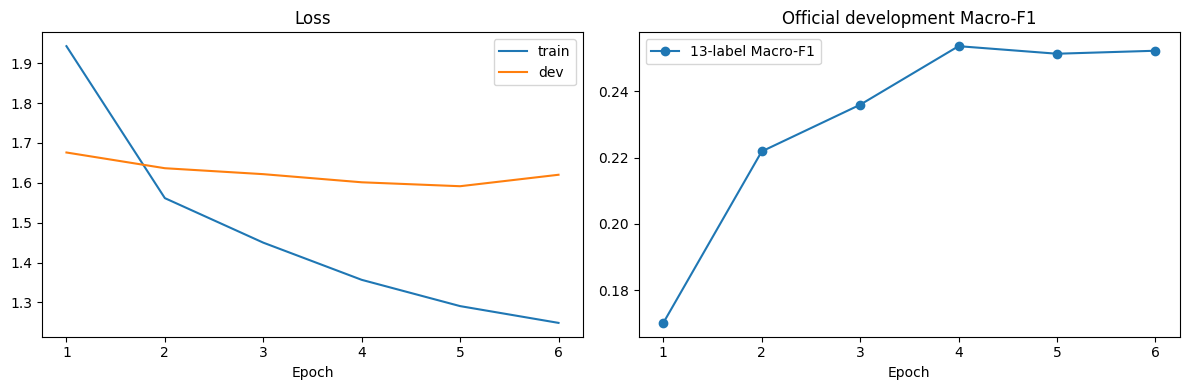

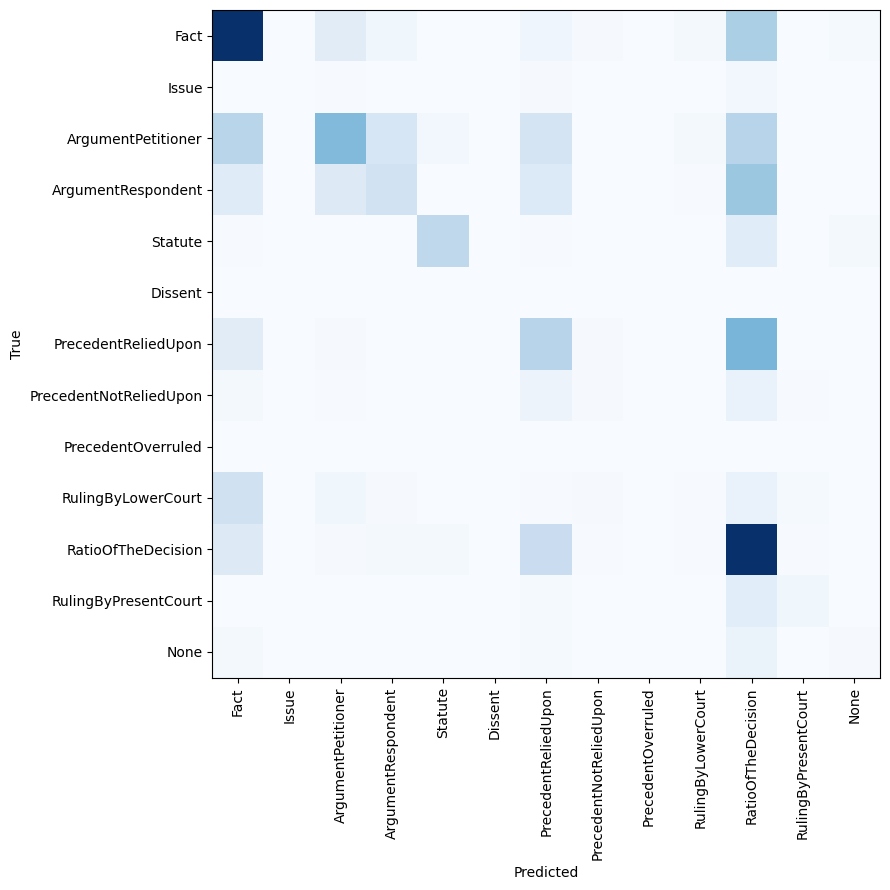

858444

In [15]:
gold,pred,records,dev_loss=predict_loader(dev_loader)
metrics=official_metrics(gold,pred)
print('Official fixed-13-label dev metrics:',json.dumps(metrics,indent=2))
print(classification_report(gold,pred,labels=list(range(N_CLASSES)),target_names=labels,zero_division=0,digits=3))
for d in ('CL','IT'):
    ix=[i for i,r in enumerate(records) if r['domain']==d]
    print('DOMAIN',d,'sentences',len(ix),official_metrics([gold[i] for i in ix],[pred[i] for i in ix]))
print('True support:',dict(zip(labels,np.bincount(gold,minlength=N_CLASSES).tolist())))
print('Predicted counts:',dict(zip(labels,np.bincount(pred,minlength=N_CLASSES).tolist())))

conf=confusion_matrix(gold,pred,labels=list(range(N_CLASSES)))
np.save(OUTPUT_DIR/'dev_confusion_matrix.npy',conf)
(OUTPUT_DIR/'dev_classification_report.txt').write_text(
    classification_report(gold,pred,labels=list(range(N_CLASSES)),target_names=labels,zero_division=0,digits=4),encoding='utf-8')
(OUTPUT_DIR/'dev_metrics.json').write_text(json.dumps(metrics,indent=2),encoding='utf-8')

fig,ax=plt.subplots(1,2,figsize=(12,4))
ax[0].plot([r['epoch'] for r in history],[r['train_loss'] for r in history],label='train')
ax[0].plot([r['epoch'] for r in history],[r['dev_loss'] for r in history],label='dev')
ax[0].set_title('Loss');ax[0].set_xlabel('Epoch');ax[0].legend()
ax[1].plot([r['epoch'] for r in history],[r['macro_f1'] for r in history],marker='o',label='13-label Macro-F1')
ax[1].set_title('Official development Macro-F1');ax[1].set_xlabel('Epoch');ax[1].legend()
plt.tight_layout();plt.savefig(OUTPUT_DIR/'training_history.png',dpi=140);plt.show()

plt.figure(figsize=(11,9));plt.imshow(conf,cmap='Blues');plt.xticks(range(N_CLASSES),labels,rotation=90)
plt.yticks(range(N_CLASSES),labels);plt.xlabel('Predicted');plt.ylabel('True');plt.tight_layout()
plt.savefig(OUTPUT_DIR/'dev_confusion_matrix.png',dpi=140);plt.show()

# Keep example-level outputs for auditing, never as training labels.
dev_inspection=[dict(domain=r['domain'],doc_id=r['doc_id'],sent_idx=r['sent_idx'],text=r['sentence'],
                     gold=labels[y],pred=labels[p]) for r,y,p in zip(records,gold,pred)]
(OUTPUT_DIR/'dev_predictions_diagnostic.json').write_text(json.dumps(dev_inspection,indent=2),encoding='utf-8')

## 13 · Exact competition JSON and ZIP: ordered list of labels per document

In [16]:
_,test_pred,test_records,_=predict_loader(test_loader)
assert len(test_pred)==len(test_rows)

def form_predictions(docs,records,predictions):
    from collections import defaultdict
    index=defaultdict(dict)
    for r,p in zip(records,predictions):
        key=(r['domain'],r['doc_id'])
        if r['sent_idx'] in index[key]: raise AssertionError('Duplicate sentence index')
        index[key][r['sent_idx']]=labels[p]
    outputs={'CL':{},'IT':{}}
    for doc in docs:
        k=(doc['domain'],doc['id'])
        slots=index.get(k,{})
        assert len(slots)==len(doc['text']),f'Missing predictions {k}'
        assert set(slots)==set(range(len(doc['text']))),f'Bad ordering {k}'
        outputs[doc['domain']][doc['id']]=[slots[i] for i in range(len(doc['text']))]
    return outputs

by_domain=form_predictions(test_docs,test_records,test_pred)
for dom in ('CL','IT'):
    (OUTPUT_DIR/f'{dom}_prediction.json').write_text(json.dumps(by_domain[dom],ensure_ascii=False,indent=2),encoding='utf-8')
    print(dom,'docs',len(by_domain[dom]),'sentences',sum(map(len,by_domain[dom].values())))

collision=set(by_domain['CL']).intersection(by_domain['IT'])
if collision:
    print('WARNING: overlapping CL/IT doc IDs. Cannot make a lossless combined JSON:',sorted(collision)[:8])
    print('Saved separate domain JSONs; check competition submission rules.')
else:
    merged={**by_domain['CL'],**by_domain['IT']}
    pred_path=OUTPUT_DIR/'prediction.json'
    pred_path.write_text(json.dumps(merged,ensure_ascii=False,indent=2),encoding='utf-8')
    submission=OUTPUT_DIR/'submission.zip'
    with zipfile.ZipFile(submission,'w',zipfile.ZIP_DEFLATED) as z: z.write(pred_path,arcname='prediction.json')
    with zipfile.ZipFile(submission) as z:
        assert z.namelist()==['prediction.json']
        assert json.loads(z.read('prediction.json'))==merged
    print('Submission:',submission)

print('Diagnostic outputs:', sorted(p.name for p in OUTPUT_DIR.iterdir()))

CL docs 5 sentences 1339
IT docs 5 sentences 858
Submission: /kaggle/working/phase3_model2_audited/submission.zip
Diagnostic outputs: ['CL_prediction.json', 'IT_prediction.json', 'best_model2_audited_fft.pt', 'data_audit.json', 'dev_classification_report.txt', 'dev_confusion_matrix.npy', 'dev_confusion_matrix.png', 'dev_metrics.json', 'dev_predictions_diagnostic.json', 'history.json', 'prediction.json', 'submission.zip', 'training_history.png']


## How to interpret this experiment

- If **TF-IDF greatly exceeds frozen probes**, the pretrained representation or its pooling is likely the bottleneck; examine tokenization/checkpoint quality and data differences.
- If **frozen probes are good but full fine-tuning collapses**, prioritize training instability, loss, and backbone LR rather than architecture complexity.
- If **train loss falls while dev loss rises**, that indicates overfitting / confidence miscalibration. Don't optimize accuracy at the expense of Macro-F1.
- If **some labels have zero training examples**, no supervised model can learn them from this Phase 3 split. The official 13-label score will retain their contribution as zeros if evaluated with all 13 labels.
- CL and IT metrics must be considered separately; domain IDs are features but **no labels cross the train/dev boundary**.

**Ablations (one at a time):** `POOLING='mean'` vs `'last'`; `USE_CLASS_WEIGHTS` True/False; `USE_PREVIOUS_CONTEXT` True/False; `MAX_LENGTH` 256/320/384. Keep the identical dev set and 13-label scorer. These are hyperparameter ablations of **one full-fine-tuning technique**, not separate mandatory capstone methods.

No actual competition performance is claimed until you run on the real checkpoint and official splits.